# Distinguish process variation from uncertainty

**Question:** How does the distinguish process variation from uncertainty analysis change when the same authored ore is run at controlled throughput settings?

Level: 1. Prerequisites: Level 1 of learning. Reading time: 18 minutes.

## Objectives

Read the committed uncertainty record, identify its uncertain ore inputs and output quantiles, and explain why an interval around one simulated state is not a plant confidence interval.

## Setup

```bash
pip install numpy==2.2.6 scipy==1.17.1 pandas==2.2.3 matplotlib==3.11.2 nbclient==0.11.0 nbformat==5.11.1 ipykernel==7.4.0 SALib==1.6.0
```

The OreFlow pipeline is imported from `data-pipeline/`; this notebook never installs packages.

Configure imports and record versions. This makes the method run reproducible.

In [1]:
# Import analysis tools and record their exact versions.
import importlib.metadata
import json
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Resolve the local pipeline from the repository-relative layout.
repo = Path("../../../").resolve()
sys.path.insert(0, str(repo / "data-pipeline"))
for package in ("numpy", "scipy", "pandas", "matplotlib", "nbclient", "nbformat", "ipykernel"):
    print(package, importlib.metadata.version(package))


numpy 2.2.6
scipy 1.17.1
pandas 2.2.3
matplotlib 3.11.2
nbclient 0.11.0
nbformat 5.11.1
ipykernel 7.4.0


## Data

Owner: OreFlow authors; `data/derived/benchmark.json` and `data/derived/studies.json`, MIT project licence. The ranges are authored uncertainty assumptions applied to authored process cases; labels are simulated. Repository: https://github.com/fsantibanezleal/CAOS_OreFlow.

## Method

OreFlow varies work index, head grade, liberation size and floatability within declared multiplicative ranges, then re-solves the same steady-state circuit. A seeded Latin hypercube produces reproducible samples. Quantiles describe this model and these ranges; they are not estimates of field measurement error or plant-to-plant variability.

Load the uncertainty quantiles and the repeated-seed study for the same authored case.

In [2]:
# Load the uncertainty quantiles and the repeated-seed study for the same authored case.
repo = Path("../../../").resolve()
benchmark = json.loads((repo / "data/derived/benchmark.json").read_text(encoding="utf-8"))
studies = json.loads((repo / "data/derived/studies.json").read_text(encoding="utf-8"))
record = benchmark["uncertainty"]["copper_porphyry_soft"]
seed_study = studies["cases"]["copper_porphyry_soft"]["seed_study"]
print(
    "design:",
    seed_study["design"],
    "| samples:",
    seed_study["samples"],
    "| seeds:",
    len(seed_study["seeds"]),
)
display(
    pd.DataFrame(
        [
            {"output": name, **summary}
            for name, summary in record.items()
            if isinstance(summary, dict) and "p50" in summary
        ]
    ).set_index("output")
)


design: Latin hypercube | samples: 128 | seeds: 8


,p05,p50,p95
output,,,
recovery_pct,89.410940,91.897183,93.795676
concentrate_grade,24.868232,26.441278,27.709650


Compare the input that dominates recovery spread with the P05-P95 output range. These are properties of the declared simulation envelope.

In [3]:
# Compare the input that dominates recovery spread with the P05-P95 output range.
print("dominant input by output:", record["dominant_input"])
print("all-constraint probability:", record["probabilities"]["all_constraints"])
seed_rows = pd.DataFrame(
    [
        {
            "seed": item["seed"],
            "recovery P05": item["recovery_pct"]["p05"],
            "recovery P50": item["recovery_pct"]["p50"],
            "recovery P95": item["recovery_pct"]["p95"],
            "all constraints": item["all_constraints"],
        }
        for item in seed_study["per_seed"]
    ]
)
display(seed_rows)


dominant input by output: {'recovery_pct': 'floatability', 'concentrate_grade': 'liberation_size', 'specific_energy_grinding_kwh_t': 'work_index', 'recovered_primary_tph': 'head_grade'}
all-constraint probability: 0.8203125


,seed,recovery P05,recovery P50,recovery P95,all constraints
0,101,89.216297,91.996411,94.025237,0.820312
1,202,89.018685,91.983648,94.034888,0.820312
2,303,89.042295,91.985040,93.914918,0.812500
3,404,89.367639,91.975672,93.875840,0.812500
4,505,89.079242,92.035955,93.745444,0.820312
5,606,89.087326,91.944077,93.799518,0.812500
6,707,89.374171,92.092473,94.007753,0.812500
7,808,89.294996,91.917077,93.948797,0.812500


For the level 1 05 uncertainty case, only fresh-feed rate changes at 0.9 times nominal throughput. This level 1 05 uncertainty comparison at 0.9 times nominal feed uses recovery, product P80 and energy to assess the stated constraints.

In [4]:
# Re-solve the authored case at one controlled throughput setting.
from pipeline.cases.catalog import CASES
from pipeline.engine.circuit import simulate
case = next(item for item in CASES if item.id == 'copper_porphyry_soft')
factor_1 = 0.9
point_1 = case.nominal.with_values(throughput_tph=case.nominal.throughput_tph * factor_1)
response_1 = simulate(case.ore, case.plant, point_1)
print('throughput (t/h):', round(point_1.throughput_tph, 2))
print('recovery (%):', round(response_1.metrics['recovery_pct'], 3))
print('product P80 (µm):', round(response_1.metrics['p80_um'], 2))

throughput (t/h): 648.0
recovery (%): 92.996
product P80 (µm): 150.0


For the level 1 05 uncertainty case, only fresh-feed rate changes at 1.0 times nominal throughput. This level 1 05 uncertainty comparison at 1.0 times nominal feed uses recovery, product P80 and energy to assess the stated constraints.

In [5]:
# Re-solve the authored case at one controlled throughput setting.
from pipeline.cases.catalog import CASES
from pipeline.engine.circuit import simulate
case = next(item for item in CASES if item.id == 'copper_porphyry_soft')
factor_2 = 1.0
point_2 = case.nominal.with_values(throughput_tph=case.nominal.throughput_tph * factor_2)
response_2 = simulate(case.ore, case.plant, point_2)
print('throughput (t/h):', round(point_2.throughput_tph, 2))
print('recovery (%):', round(response_2.metrics['recovery_pct'], 3))
print('product P80 (µm):', round(response_2.metrics['p80_um'], 2))

throughput (t/h): 720.0
recovery (%): 92.213
product P80 (µm): 150.0


For the level 1 05 uncertainty case, only fresh-feed rate changes at 1.1 times nominal throughput. This level 1 05 uncertainty comparison at 1.1 times nominal feed uses recovery, product P80 and energy to assess the stated constraints.

In [6]:
# Re-solve the authored case at one controlled throughput setting.
from pipeline.cases.catalog import CASES
from pipeline.engine.circuit import simulate
case = next(item for item in CASES if item.id == 'copper_porphyry_soft')
factor_3 = 1.1
point_3 = case.nominal.with_values(throughput_tph=case.nominal.throughput_tph * factor_3)
response_3 = simulate(case.ore, case.plant, point_3)
print('throughput (t/h):', round(point_3.throughput_tph, 2))
print('recovery (%):', round(response_3.metrics['recovery_pct'], 3))
print('product P80 (µm):', round(response_3.metrics['p80_um'], 2))

throughput (t/h): 792.0
recovery (%): 91.437
product P80 (µm): 150.0


For level 1 05 uncertainty, the panels use identical settings and 3 solved model points rather than plant observations. At level 1, the 05 uncertainty trend is a local response from one authored case and can change near power or grade constraints; it is not a causal plant estimate.

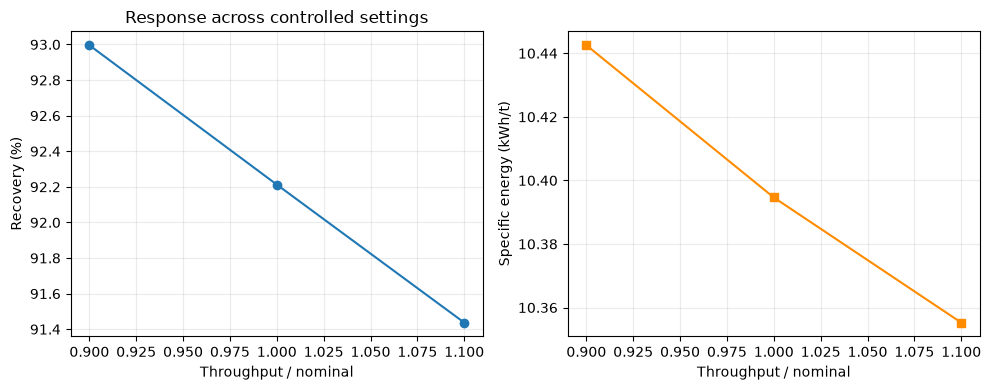

In [7]:
# Compare recovery and specific energy from the executed circuit runs.
import matplotlib.pyplot as plt
factors = [0.9, 1.0, 1.1]
runs = [response_1, response_2, response_3]
recovery = [run.metrics['recovery_pct'] for run in runs]
energy = [run.metrics['specific_energy_total_kwh_t'] for run in runs]
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(factors, recovery, marker='o')
axes[0].set(xlabel='Throughput / nominal', ylabel='Recovery (%)', title='Response across controlled settings')
axes[1].plot(factors, energy, marker='s', color='darkorange')
axes[1].set(xlabel='Throughput / nominal', ylabel='Specific energy (kWh/t)')
for axis in axes:
    axis.grid(True, alpha=0.25)
fig.tight_layout()

In the level 1 05 uncertainty analysis, read this size response alongside the recovery and energy panels rather than as a substitute. At level 1, a constant grind target in this 05 uncertainty case can keep P80 nearly unchanged while power limits, recycle and residence alter other outputs. For 05 uncertainty at level 1, retain model flags and the mass-balance audit with the result.

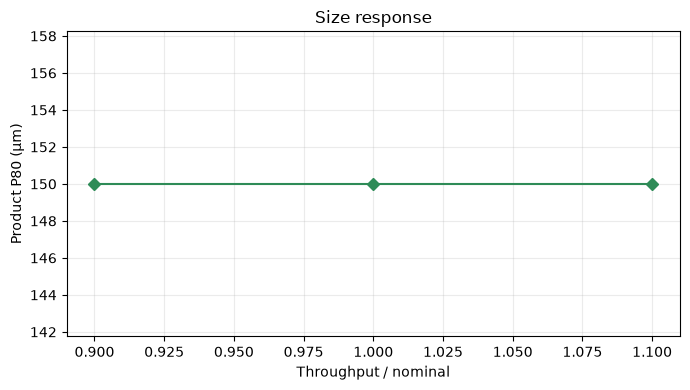

In [8]:
# Show product size separately because it is measured in micrometres, not energy or recovery.
fig, ax = plt.subplots(figsize=(7, 4))
sizes = [run.metrics['p80_um'] for run in runs]
ax.plot(factors, sizes, marker='D', color='seagreen')
ax.set(xlabel='Throughput / nominal', ylabel='Product P80 (µm)', title='Size response')
ax.grid(True, alpha=0.25)
fig.tight_layout()

At level 1 in 05 uncertainty, interpretation 1 is that a scenario spread is conditional on the chosen distributions, dependence assumptions, sample design and process equations. At level 1 in 05 uncertainty, interpretation 2 is that oreFlow's uncertainty propagation samples bounded operating and ore factors, runs the exact circuit engine and summarizes response quantiles and constraint probabilities. At level 1 in 05 uncertainty, interpretation 3 is that a Sobol decomposition asks how input variation contributes to output variance under its sampling assumptions. At level 1 in 05 uncertainty, interpretation 4 is that it does not assign probabilities to the ore body or establish causation. At level 1 in 05 uncertainty, interpretation 5 is that first-order and total-order indices answer different questions because total order includes interactions. At level 1 in 05 uncertainty, interpretation 6 is that bootstrap half-widths describe estimator stability for the design, not uncertainty about the real plant. At level 1 in 05 uncertainty, interpretation 7 is that always report the random seed, base sample count, input bounds, rejected draws and whether output was constant at numerical tolerance. At level 1 in 05 uncertainty, interpretation 8 is that independent draws can create physically implausible combinations when geological variables co-vary, while narrow bounds can make an influential factor appear unimportant. At level 1 in 05 uncertainty, interpretation 9 is that separate input uncertainty from uncertain model structure and measurement error. At level 1 in 05 uncertainty, interpretation 10 is that to interpret a decision, propagate calibrated distributions, compare predicted intervals with held-out plant campaigns and assess whether the ranking of operating choices is stable. At level 1 in 05 uncertainty, interpretation 11 is that the present authored scenarios support method inspection and reproducibility only. At level 1 in 05 uncertainty, interpretation 12 is that they do not provide a probability forecast for a mine or plant.

## Results

**Answer:** In this level 1 05 uncertainty lesson, the executed circuit reports recovery of 92.996 percent at the first controlled throughput setting for Distinguish process variation from uncertainty.

The quantiles summarize model output conditional on the authored half-widths and the chosen case. The seed study shows how estimates shift with a different design. Neither describes observational uncertainty in a real plant unless independent measurements and a justified uncertainty model support that interpretation.

## Summary

You separated a seeded model uncertainty study from measurement uncertainty. State the sampling design, input ranges and data provenance whenever quoting these results.

## References

- https://doi.org/10.1080/00401706.1979.10489755